# CSCI E-89: Problem Set 05, Problem 1

Schwartzberg, Paul

## Five transformations of a tiger photograph

This notebook applies the five transformations requested in Problem 1. Each starts from the same photograph, so the effects can be compared separately. Each transformation uses `torchvision.transforms.Compose`.

The phrase **around an axis** means reflection about that axis. Reflection about a horizontal axis swaps top and bottom; reflection about a vertical axis swaps left and right. Torchvision names its flips by the direction in which the pixels move, so `RandomVerticalFlip` performs the horizontal-axis reflection and `RandomHorizontalFlip` performs the vertical-axis reflection.

Use the **cscie89** kernel. The code runs on the CPU and needs no trained model.

## 1. Set up the tools and output folder

`Path` handles file locations. Pillow opens and resamples images. NumPy handles the diagonal stretch calculation. Matplotlib draws the results. Torchvision supplies `Compose`, flips, rotation and tensor conversion. The printed Python path identifies the environment running this notebook.

In [1]:
# Import the tools used below and show the active Python environment.
from pathlib import Path
from urllib.request import Request, urlopen
from io import BytesIO
import json
import sys

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode

ASSET_DIR = Path("assets")
OUTPUT_DIR = Path("outputs/problem1")
ASSET_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)


Python: C:\Users\schwa\.conda\envs\cscie89\python.exe
PyTorch: 2.14.0+cpu | torchvision: 0.29.0+cpu


## 2. Load a photograph at moderate resolution

The photograph shows a Bengal tiger. It is credited to John and Karen Hollingsworth of the U.S. Fish and Wildlife Service and is listed as public domain in the United States on its [Wikimedia Commons source page](https://commons.wikimedia.org/wiki/File:Panthera_tigris_tigris_original.jpg).

The saved copy is 960 x 641 pixels. This keeps the proportions of the source while giving enough detail for the demonstration. The repository includes this copy; the download runs only if it is missing. The code converts it to RGB, meaning red, green and blue colour channels.

In [2]:
# Use the saved photograph. Download it only if the local copy is missing.
TIGER_PAGE = "https://commons.wikimedia.org/wiki/File:Panthera_tigris_tigris_original.jpg"
TIGER_URL = "https://upload.wikimedia.org/wikipedia/commons/f/f9/Panthera_tigris_tigris_original.jpg"
TIGER_PATH = ASSET_DIR / "tiger.jpg"
if not TIGER_PATH.exists():
    request = Request(TIGER_URL, headers={"User-Agent": "CSCI-E89-HW5/1.0 (educational image transformations)"})
    with urlopen(request, timeout=45) as response:
        downloaded = response.read()
    with Image.open(BytesIO(downloaded)) as picture:
        picture = picture.convert("RGB")
        picture.thumbnail((960, 960))  # Keep the aspect ratio; limit the longest side.
        picture.save(TIGER_PATH, quality=92)

with Image.open(TIGER_PATH) as picture:
    tiger = picture.convert("RGB")
print("Working image:", TIGER_PATH, "| width x height:", tiger.size)


Working image: assets\tiger.jpg | width x height: (960, 641)


## 3. Define a 10% stretch along one diagonal

We choose the line from the image's top-left corner to its bottom-right corner. The stretch lengthens distances parallel to that line by 10%, while leaving distances perpendicular to it unchanged. It acts about the image centre.

The diagonal stretch needs a small custom transformation. `Compose` accepts a callable object: its `__call__` method receives an image and returns a transformed image. The calculation below finds the diagonal direction, builds the stretch, enlarges the canvas to hold the result, and samples the source image.

For the numerical calculation, `u` is a unit vector along the diagonal. The matrix is `A = I + 0.10 * outer(u, u)`. It gives `A @ u = 1.10 * u` and leaves a perpendicular vector unchanged. Pillow uses the inverse matrix because it works backwards from each output pixel to the corresponding source position. Bilinear interpolation estimates values between source pixels; the new border is white.

In [3]:
class DiagonalStretch:
    """Stretch along the image's top-left to bottom-right diagonal about its centre."""

    def __init__(self, factor=1.10, fill=(255, 255, 255)):
        self.factor = float(factor)
        self.fill = fill
        if self.factor < 1:
            raise ValueError("This demonstration expects a stretch factor of at least one.")

    def __call__(self, image):
        width, height = image.size
        # A unit vector gives the diagonal's direction, including a non-square image.
        diagonal = np.array([width, height], dtype=float)
        diagonal /= np.linalg.norm(diagonal)
        # Add 10% only to the component parallel to that diagonal.
        forward = np.eye(2) + (self.factor - 1) * np.outer(diagonal, diagonal)
        # Positive entries let us find the bounding canvas from width and height.
        out_width, out_height = np.ceil(forward @ [width, height]).astype(int)
        original_centre = np.array([width, height], dtype=float) / 2
        output_centre = np.array([out_width, out_height], dtype=float) / 2
        # Pillow needs the reverse mapping: for each output pixel, where to sample.
        inverse = np.linalg.inv(forward)
        offset = original_centre - inverse @ output_centre
        coefficients = (
            inverse[0, 0], inverse[0, 1], offset[0],
            inverse[1, 0], inverse[1, 1], offset[1],
        )
        return image.transform(
            (int(out_width), int(out_height)), Image.Transform.AFFINE,
            coefficients, resample=Image.Resampling.BILINEAR, fillcolor=self.fill,
        )


## 4. Build five separate Compose pipelines

Each pipeline first changes the photograph, then calls `ToTensor`. For an RGB image, `ToTensor` stores three channels, puts channels before height and width, and scales pixel values from 0-255 to 0-1.

Setting the flip probability to `1.0` makes the change happen every time. A rotation interval such as `(10, 10)` fixes the angle at 10 degrees. Positive rotation angles turn left (counter-clockwise); negative angles turn right (clockwise). `expand=True` enlarges the canvas to keep the rotated corners. The white border fills space outside the transformed photograph.

The five operations are separate. Applying all five in one pipeline would produce one combined transformation and hide their individual effects. See the [Compose documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Compose.html) and [rotation documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.functional.rotate.html).

In [4]:
# Each Compose starts from the same photograph and ends with tensor conversion.
# p=1 forces the flips to happen; equal rotation bounds fix the angle.
tiger_transforms = {
    "horizontal_axis_flip": transforms.Compose([
        transforms.RandomVerticalFlip(p=1.0),  # Reflection about a horizontal axis.
        transforms.ToTensor(),
    ]),
    "vertical_axis_flip": transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),  # Reflection about a vertical axis.
        transforms.ToTensor(),
    ]),
    "diagonal_stretch_10_percent": transforms.Compose([
        DiagonalStretch(factor=1.10),
        transforms.ToTensor(),
    ]),
    "rotate_left_10_degrees": transforms.Compose([
        transforms.RandomRotation((10, 10), interpolation=InterpolationMode.BILINEAR,
                                  expand=True, fill=255),
        transforms.ToTensor(),
    ]),
    "rotate_right_15_degrees": transforms.Compose([
        transforms.RandomRotation((-15, -15), interpolation=InterpolationMode.BILINEAR,
                                  expand=True, fill=255),
        transforms.ToTensor(),
    ]),
}
# Each tensor has shape (three colour channels, height, width), with values in [0, 1].
tiger_results = {name: pipeline(tiger) for name, pipeline in tiger_transforms.items()}


## 5. Check the diagonal scale

This short calculation checks the geometry. A unit length along the chosen diagonal becomes 1.10 units; a unit length perpendicular to it stays 1.00 units. Image interpolation can alter individual pixel values, but it does not change the intended geometric scale.

In [5]:
# Check the mathematical meaning of the stretch independently of the photograph.
u = np.array(tiger.size, dtype=float)
u /= np.linalg.norm(u)
v = np.array([-u[1], u[0]])  # A unit direction perpendicular to the chosen diagonal.
A = np.eye(2) + 0.10 * np.outer(u, u)
print(f"Length scale along the diagonal: {np.linalg.norm(A @ u):.2f}")
print(f"Length scale across the diagonal: {np.linalg.norm(A @ v):.2f}")
print("These are the geometric scales before resampling pixels.")


Length scale along the diagonal: 1.10
Length scale across the diagonal: 1.00
These are the geometric scales before resampling pixels.


## 6. Display and save the results

The figure shows the original and five transformed versions. `permute(1, 2, 0)` places the tensor dimensions in the order Matplotlib needs: height, width, channels. The titles state the operation and output size. We save each transformed PNG, the comparison figure and a JSON record of the settings.

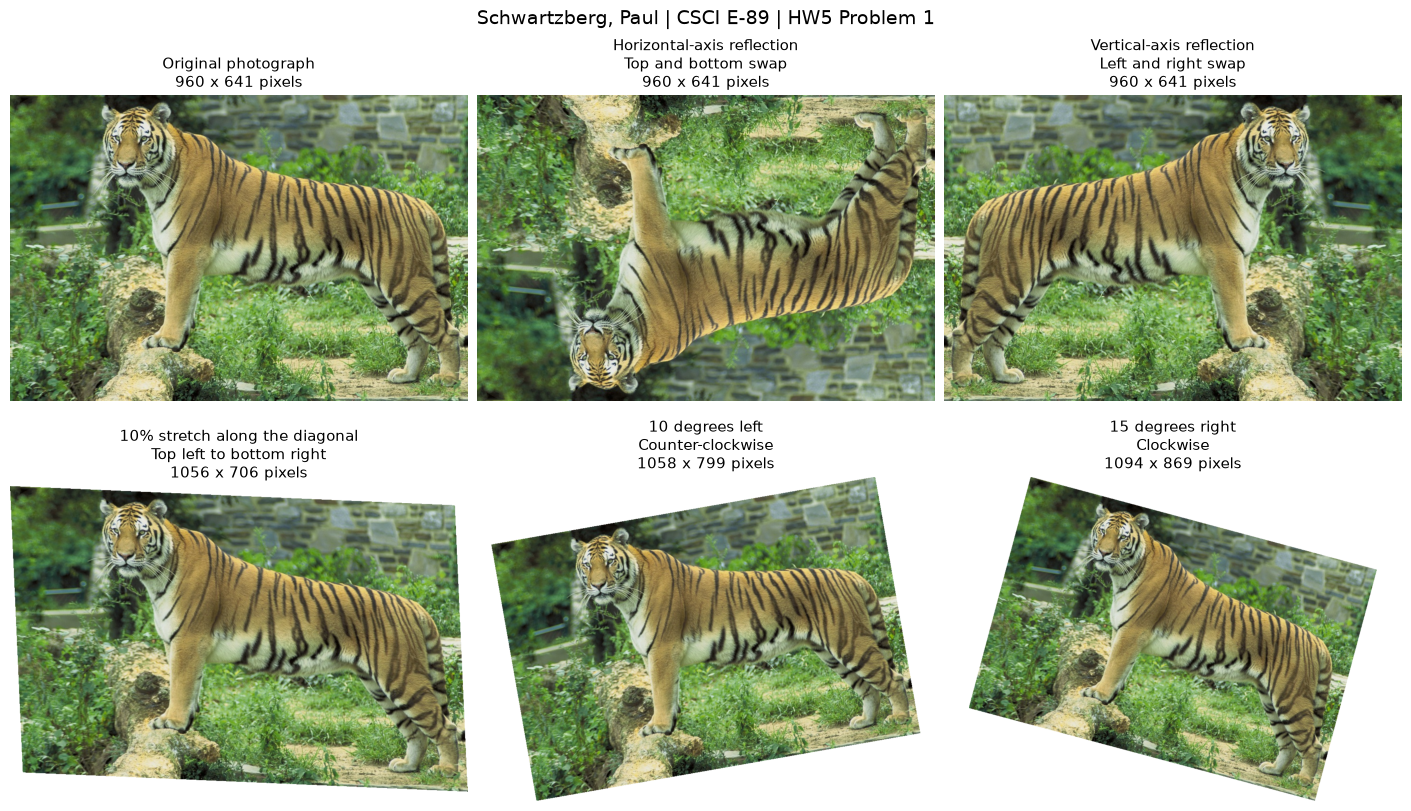

Saved the five transformed images, comparison plot and transformation record in outputs\problem1


In [6]:
# Display the original and five separate results; save a static report and images.
labels = {
    "horizontal_axis_flip": "Horizontal-axis reflection\nTop and bottom swap",
    "vertical_axis_flip": "Vertical-axis reflection\nLeft and right swap",
    "diagonal_stretch_10_percent": "10% stretch along the diagonal\nTop left to bottom right",
    "rotate_left_10_degrees": "10 degrees left\nCounter-clockwise",
    "rotate_right_15_degrees": "15 degrees right\nClockwise",
}
shown = {"original": transforms.ToTensor()(tiger), **tiger_results}
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
manifest = {"author": "Schwartzberg, Paul", "source_page": TIGER_PAGE,
            "source_url": TIGER_URL, "image_credit": "John and Karen Hollingsworth, U.S. Fish and Wildlife Service; public domain in the United States",
            "stretch_factor": 1.10, "results": {}}
for ax, (name, tensor) in zip(axes.flat, shown.items()):
    # Matplotlib expects height, width, channels; tensors store channels first.
    ax.imshow(tensor.permute(1, 2, 0).numpy())
    title = "Original photograph" if name == "original" else labels[name]
    ax.set_title(f"{title}\n{tensor.shape[2]} x {tensor.shape[1]} pixels", fontsize=11)
    ax.axis("off")
    if name != "original":
        transforms.ToPILImage()(tensor).save(OUTPUT_DIR / f"{name}.png")
    manifest["results"][name] = {"tensor_shape": list(tensor.shape), "width": tensor.shape[2], "height": tensor.shape[1]}
fig.suptitle("Schwartzberg, Paul | CSCI E-89 | HW5 Problem 1", fontsize=14)
fig.savefig(OUTPUT_DIR / "tiger_transformations.png", dpi=120)
plt.show()
(OUTPUT_DIR / "transformations.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved the five transformed images, comparison plot and transformation record in", OUTPUT_DIR)


## Observations

The horizontal-axis reflection puts the tiger upside down. The vertical-axis reflection moves its head to the other side. The diagonal stretch changes the tiger's proportions slightly along the chosen diagonal. The two rotations tilt the photograph by the requested angles; their canvases grow to keep the full photograph.

These examples show how image transformations change orientation and shape. Their suitability as training augmentation depends on the task: an upside-down tiger is useful for showing a flip, but may be uncommon in the images a classifier will receive.

**Problem 1 is complete.** The code, source image, five transformations, comparison figure and HTML export are saved with this solution. Problems 2-4 will be developed separately.